<a href="https://colab.research.google.com/github/WendelLeander/PhishEvade/blob/main/model_training_tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model Training and Tuning
### Obfuscation-Aware Feature Engineering for Phishing URL Detection

This notebook is responsible for the model training and tuning phase of the research. To be specific, this notebook does the following:

1. Re-establish the **baseline reference** (Logistic Regression, Level 1) so every other combination is compared against it.
2. Train **five classifiers** (Random Forest, XGBoost, Logistic Regression, Naive Bayes, AdaBoost) across **three feature configurations** (Level 1 only, Level 2 only, Level 1 + Level 2 combined): **5 x 3 = 15 model-feature combinations**.
3. Use the **same 80 / 20 stratified split** as the baseline and tune every combination with **GridSearchCV and 5-fold cross-validation** on the training set only.
4. **Persist all 15 trained and tuned models** so the formal testing stage can load them.

**Feature configurations**

| Configuration | Columns | Count |
|---|---|---|
| Level 1 | `url_length`, `domain_length`, `path_length` | 3 |
| Level 2 | `subdomain_count`, `path_depth`, `query_params_count`, `digit_ratio`, `special_char_ratio`, `token_variance`, `domain_entropy`, `redirect_key_flag`, `nested_url_flag`, `query_encoding_ratio` | 10 |
| Combined | Level 1 + Level 2 | 13 |

**Pipeline**

| Step | Procedure | Output |
|---|---|---|
| 1. Training / Hold-Out Split (80 / 20) | Reuse the baseline’s stratified split (same seed) | Same train set and untouched test set |
| 2. Resource Instrumentation | Define the profiler for training time and peak memory | `ResourceProfiler` |
| 3. The Five Classifiers and Their Hyperparameter Grids | Define the five classifiers and their grids | Estimators and grids |
| 4. Training Routine | GridSearchCV with 5-fold CV (F1, train set only), Youden’s J threshold tuning, per-URL inference timing, hold-out sanity score | One tuned model with its metrics and resource figures|
| 5. Train and Tune All 15 Model-Feature Combinations | Run the routine for every classifier on every feature set and save each model as it finishes | 15 tuned models (`.joblib`) |
| 6. Baseline Reference and Comparison | Re-derive the baseline and compare all 15 against it at the 0.5 threshold | Baseline metrics, comparison table and chart |
| 7. Best Hyperparameters and Computational Cost | Report tuned hyperparameters, CV F1, threshold, training time, memory and latency | Summary table |
| 8. Persist and Verify | Reload all 15 models and confirm they reproduce their predictions. Write the metrics CSV and JSON and the manifest | Verified models and summary files |
| 9. Completion Check | Assert that the baseline is recorded and all 15 models exist | “Ready for testing” confirmation |

## Install Dependencies (run once)

`%pip` installs into the **same Python environment the notebook kernel is using**. If an import error persists after installing, restart the kernel and run the notebook again.

In [24]:
# Run once. Safe to re-run; already-installed packages are skipped.
%pip install -q pandas numpy scikit-learn xgboost matplotlib psutil joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 0. Setup and Input Data
Same input as the baseline: `Final Dataset_Scaled.csv` with the 13 scaled features and the binary `label` (`0` = benign, `1` = phishing, the **positive class**). Every random operation uses `RANDOM_SEED`, so the whole notebook is reproducible.

All five classifiers are given `n_jobs=1` and the grid searches run single-process so that `psutil` sees all of the work and the resource figures are comparable between models.

In [25]:
import os, time, json, threading, platform, hashlib, warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil, joblib, sklearn, xgboost

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import confusion_matrix

from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

# DATA_PATH = "../Dataset/Final_Dataset.csv"  # Local path
DATA_PATH         = "https://raw.githubusercontent.com/WendelLeander/PhishEvade/refs/heads/main/Dataset/Final_Dataset.csv"
RANDOM_SEED       = 42
TEST_SIZE         = 0.20            # 80 / 20 split (same as the baseline)
N_FOLDS           = 5               # k-fold cross-validation on the training set
DEFAULT_THRESHOLD = 0.5             # the study's stated decision rule

LEVEL1_FEATURES = ["url_length", "domain_length", "path_length"]
LEVEL2_FEATURES = ["subdomain_count", "path_depth", "query_params_count", "digit_ratio", "special_char_ratio",
                   "token_variance", "domain_entropy", "redirect_key_flag", "nested_url_flag", "query_encoding_ratio"]
FEATURE_SETS = {
    "Level 1":  LEVEL1_FEATURES,
    "Level 2":  LEVEL2_FEATURES,
    "Combined": LEVEL1_FEATURES + LEVEL2_FEATURES,
}

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name.lower() == "modules":
    BASE_DIR = CURRENT_DIR.parent
else:
    BASE_DIR = CURRENT_DIR

# Output directories
MODEL_DIR = BASE_DIR / "Models"
METRICS_DIR = BASE_DIR / "Metrics"

# Create directories if necessary
MODEL_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

print("Models directory:", MODEL_DIR)
print("Metrics directory:", METRICS_DIR)

MODEL_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| psutil", psutil.__version__)

Models directory: c:\Users\OWEn\Desktop\SCHOOL\## THESIS\THSN02\PhishEvade\Models
Metrics directory: c:\Users\OWEn\Desktop\SCHOOL\## THESIS\THSN02\PhishEvade\Metrics
scikit-learn 1.7.1 | xgboost 3.4.1 | numpy 2.2.5 | pandas 2.2.3 | psutil 7.0.0


In [26]:
data = pd.read_csv(DATA_PATH)
needed = LEVEL1_FEATURES + LEVEL2_FEATURES + ["label"]
missing = [c for c in needed if c not in data.columns]
assert not missing, f"missing columns in {DATA_PATH}: {missing}"
assert set(LEVEL1_FEATURES).isdisjoint(LEVEL2_FEATURES)

y_all = data["label"].to_numpy(dtype=np.int64)
assert np.isfinite(data[needed].to_numpy(dtype=np.float64)).all()

print(f"Loaded {len(data):,} rows | Level 1: {len(LEVEL1_FEATURES)} features | Level 2: {len(LEVEL2_FEATURES)} features | "
      f"Combined: {len(FEATURE_SETS['Combined'])} features")
print("Class balance:", {int(k): int(v) for k, v in zip(*np.unique(y_all, return_counts=True))}, "(0 = benign, 1 = phishing)")

Loaded 10,000 rows | Level 1: 3 features | Level 2: 10 features | Combined: 13 features
Class balance: {0: 5000, 1: 5000} (0 = benign, 1 = phishing)


## 1. Training / Hold-Out Split (80 / 20)
The split code and seed are **identical to the baseline notebook** (`train_test_split` on row positions, stratified by class, `random_state=42`), so every model here is trained and evaluated on exactly the same rows as the baseline. If `train_test_split_indices.csv` from the baseline run is present, the cell below also verifies that the split matches it row for row.

In [27]:
train_idx, test_idx = train_test_split(
    np.arange(len(y_all)), test_size=TEST_SIZE, stratify=y_all, random_state=RANDOM_SEED)
y_train, y_test = y_all[train_idx], y_all[test_idx]

# Cross-check against the split the baseline notebook saved (if that file is available)
if os.path.exists("../Models/train_test_split_indices.csv"):
    saved = pd.read_csv("../Models/train_test_split_indices.csv")
    saved_test = np.sort(saved.loc[saved["split"] == "test", "row_index"].to_numpy())
    assert np.array_equal(saved_test, np.sort(test_idx)), "split differs from the baseline's saved split!"
    print("Split verified: identical to the baseline's train_test_split_indices.csv")
else:
    print("train_test_split_indices.csv not found here; the split is reproduced from the same seed and settings.")

pd.DataFrame({
    "rows": [len(y_train), len(y_test)],
    "benign (0)":   [int((y_train == 0).sum()), int((y_test == 0).sum())],
    "phishing (1)": [int((y_train == 1).sum()), int((y_test == 1).sum())],
}, index=["training (80%)", "hold-out test (20%)"])

Split verified: identical to the baseline's train_test_split_indices.csv


,rows,benign (0),phishing (1)
training (80%),8000,4000,4000
hold-out test (20%),2000,1000,1000


## 2. Resource Instrumentation (`psutil`)
The same `ResourceProfiler` as the baseline: it logs wall-clock time, CPU time and utilisation, and **peak resident memory** (sampled every 10 ms in a background thread) for a phase. It wraps each combination's full training process (grid search, 5-fold CV and refit). Inference latency is measured separately per URL.

In [28]:
class ResourceProfiler:
    '''Context manager: wall time, CPU time/utilisation and peak memory of a phase (via psutil).'''

    def __init__(self, phase, interval=0.01):
        self.phase, self.interval, self.record = phase, interval, None

    def __enter__(self):
        self.proc = psutil.Process(os.getpid())
        self.proc.cpu_percent(None)                       # prime psutil's CPU-utilisation counter
        self.cpu0 = self.proc.cpu_times()
        self.rss0 = self.proc.memory_info().rss
        self.peak = self.rss0
        self._stop = threading.Event()
        self._thread = threading.Thread(target=self._poll, daemon=True)
        self.start_dt, self.t0 = datetime.now(), time.perf_counter()
        self._thread.start()
        return self

    def _poll(self):
        while not self._stop.is_set():
            self.peak = max(self.peak, self.proc.memory_info().rss)
            time.sleep(self.interval)

    def __exit__(self, *exc):
        wall = time.perf_counter() - self.t0
        self._stop.set(); self._thread.join()
        self.peak = max(self.peak, self.proc.memory_info().rss)
        cpu1 = self.proc.cpu_times()
        self.record = {
            "phase": self.phase,
            "start": self.start_dt.strftime("%H:%M:%S"),
            "end": datetime.now().strftime("%H:%M:%S"),
            "wall_time_s": wall,
            "cpu_time_s": (cpu1.user + cpu1.system) - (self.cpu0.user + self.cpu0.system),
            "cpu_util_pct": self.proc.cpu_percent(None),
            "peak_memory_mb": self.peak / 2**20,
            "peak_memory_increase_mb": (self.peak - self.rss0) / 2**20,
        }
        return False

print("ResourceProfiler ready |", psutil.cpu_count(logical=True), "logical CPUs |",
      round(psutil.virtual_memory().total / 2**30, 1), "GB RAM")

ResourceProfiler ready | 22 logical CPUs | 15.4 GB RAM


## 3. The Five Classifiers and Their Hyperparameter Grids
Each classifier gets a grid sized to be meaningful but affordable: **15 combinations x grid size x 5 folds** model fits are run in total. The Logistic Regression grid is **exactly the baseline's**, so the Level 1 Logistic Regression reproduces the baseline result.

| Classifier | Hyperparameters searched | Why these |
|---|---|---|
| **Logistic Regression** | `C` (9 values, 0.001 to 100,000), `class_weight` (none, balanced), `solver` (lbfgs, liblinear) | Same as baseline, regularisation strength matters most on these small, scaled features |
| **Random Forest** | | |
| **XGBoost** | | |
| **Naive Bayes** (Gaussian) | | |
| **AdaBoost** | | |

Tuning is scored by **F1** (the study's primary benchmark), as in the baseline. Tree models are insensitive to feature scaling and Gaussian NB handles the mixed scales, so no extra scaling is applied. The features are used exactly as in the scaled CSV.

In [29]:
def make_classifiers():
    # Fresh estimator + grid per combination. Every model is single-process and seeded.
    return {
        "Logistic Regression": (
            LogisticRegression(max_iter=5000, random_state=RANDOM_SEED),
            {"C": [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000],
             "class_weight": [None, "balanced"],
             "solver": ["lbfgs", "liblinear"]}),
        "Random Forest": (
            RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=1),
            {"n_estimators": [100, 300],
             "max_depth": [None, 10, 20],
             "min_samples_leaf": [1, 3, 5]}),
        "XGBoost": (
            XGBClassifier(eval_metric="logloss", tree_method="hist", n_jobs=1, random_state=RANDOM_SEED),
            {"n_estimators": [100, 300],
             "max_depth": [3, 5, 7],
             "learning_rate": [0.05, 0.1, 0.2]}),
        "Naive Bayes": (
            GaussianNB(),
            {"var_smoothing": [float(v) for v in np.logspace(-9, 0, 10)]}),
        "AdaBoost": (
            AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_SEED), random_state=RANDOM_SEED),
            {"n_estimators": [50, 100, 200],
             "learning_rate": [0.01, 0.1, 1.0],
             "estimator__max_depth": [1, 2, 3]}),
    }

CLASSIFIERS = list(make_classifiers())
total_fits = 0
for name, (_, grid_) in make_classifiers().items():
    n_c = int(np.prod([len(v) for v in grid_.values()]))
    total_fits += n_c * N_FOLDS * len(FEATURE_SETS)
    print(f"{name:<20}: {n_c:>3} candidate configurations x {N_FOLDS} folds = {n_c * N_FOLDS:>4} fits per feature set")
print(f"\n{len(CLASSIFIERS)} classifiers x {len(FEATURE_SETS)} feature sets = {len(CLASSIFIERS) * len(FEATURE_SETS)} combinations "
      f"| {total_fits:,} grid-search fits in total (plus refits and threshold-tuning folds)")

Logistic Regression :  36 candidate configurations x 5 folds =  180 fits per feature set
Random Forest       :  18 candidate configurations x 5 folds =   90 fits per feature set
XGBoost             :  18 candidate configurations x 5 folds =   90 fits per feature set
Naive Bayes         :  10 candidate configurations x 5 folds =   50 fits per feature set
AdaBoost            :  27 candidate configurations x 5 folds =  135 fits per feature set

5 classifiers x 3 feature sets = 15 combinations | 1,635 grid-search fits in total (plus refits and threshold-tuning folds)


## 4. Training Routine

`train_combination` runs the full procedure for one classifier-feature pair and returns everything that needs recording:

1. **GridSearchCV** over the classifier's grid with 5-fold stratified CV on the training rows, scored by F1, then refit on the whole training set (this whole step is profiled).
2. **Threshold tuning**: out-of-fold probabilities from the same 5 folds, thresholds swept from 0.01 to 0.99, and the one maximising **Youden's J** (recall minus false positive rate) chosen, with ties going to the value closest to 0.5. F1 is not used for this because, for a weak classifier, it drifts toward flagging nearly every URL as phishing (see the baseline notebook, Section 4).
3. **Sanity scoring** of the hold-out set at both the default (0.5) and the tuned threshold, plus **single-URL inference latency**.

The helper `metrics_at` is the same as in the baseline.

In [30]:
def metrics_at(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)                 # score >= threshold -> phishing
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall    = tp / (tp + fn) if (tp + fn) else 0.0
    fpr       = fp / (fp + tn) if (fp + tn) else 0.0
    return {
        "threshold": float(threshold),
        "accuracy":  (tp + tn) / (tp + tn + fp + fn),
        "precision": precision,
        "recall":    recall,
        "f1":        (2 * precision * recall / (precision + recall)) if (precision + recall) else 0.0,
        "fpr":       fpr,
        "youden_j":  recall - fpr,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

THRESHOLDS = np.round(np.arange(0.01, 1.00, 0.01), 2)
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)   # same folds as the baseline
WARMUP = 50

def grid_edge_params(best_params, grid_):
    '''Numeric hyperparameters whose best value sits on the edge of a grid with 3+ values (a hint to widen the grid).'''
    edge = []
    for k, v in best_params.items():
        vals = [x for x in grid_[k] if x is not None and not isinstance(x, str)]
        if v is None or isinstance(v, str) or len(vals) < 3:
            continue
        if v in (min(vals), max(vals)):
            edge.append(k)
    return edge

def train_combination(clf_name, fs_name):
    cols = FEATURE_SETS[fs_name]
    X_tr = data.iloc[train_idx][cols].to_numpy(dtype=np.float64)
    X_te = data.iloc[test_idx][cols].to_numpy(dtype=np.float64)
    estimator, param_grid = make_classifiers()[clf_name]

    grid = GridSearchCV(estimator, param_grid=param_grid, scoring="f1", cv=skf, n_jobs=1, refit=True)
    with ResourceProfiler(f"Training: {clf_name} / {fs_name}") as prof_train:
        grid.fit(X_tr, y_train)                                     # grid search + 5-fold CV + refit
    model = grid.best_estimator_

    with ResourceProfiler("Threshold tuning (out-of-fold)") as prof_thr:
        oof = cross_val_predict(model, X_tr, y_train, cv=skf, method="predict_proba")[:, 1]
    sweep = pd.DataFrame([metrics_at(y_train, oof, t) for t in THRESHOLDS])
    sweep["dist"] = (sweep["threshold"] - DEFAULT_THRESHOLD).abs()
    tuned_threshold = float(sweep.sort_values(["youden_j", "dist"], ascending=[False, True]).iloc[0]["threshold"])

    test_proba = model.predict_proba(X_te)[:, 1]                     # Obfuscation Score per test URL
    for i in range(WARMUP):                                          # warm-up, then time one URL per call
        model.predict_proba(X_te[i:i + 1])
    per_url = np.empty(len(X_te))
    for i in range(len(X_te)):
        t0 = time.perf_counter(); model.predict_proba(X_te[i:i + 1]); per_url[i] = time.perf_counter() - t0
    latency = {"mean_ms": float(per_url.mean() * 1000), "median_ms": float(np.median(per_url) * 1000),
               "p95_ms": float(np.percentile(per_url, 95) * 1000), "n_urls": int(len(per_url))}

    return {
        "classifier": clf_name, "feature_set": fs_name, "features": cols,
        "model": model, "best_params": grid.best_params_, "param_grid": param_grid,
        "cv_f1": float(grid.best_score_), "cv_f1_std": float(grid.cv_results_["std_test_score"][grid.best_index_]),
        "edge_params": grid_edge_params(grid.best_params_, param_grid),
        "tuned_threshold": tuned_threshold, "test_proba": test_proba,
        "test_default": metrics_at(y_test, test_proba, DEFAULT_THRESHOLD),
        "test_tuned":   metrics_at(y_test, test_proba, tuned_threshold),
        "train_resources": prof_train.record, "threshold_resources": prof_thr.record, "latency": latency,
    }
print("train_combination ready")

train_combination ready


## 5. Train and Tune All 15 Model-Feature Combinations

Each combination is trained, tuned and (immediately) persisted to `models/` as soon as it finishes, so partial progress is not lost if the run is interrupted. Progress is printed per combination. This is the long-running cell: allow several minutes.

In [31]:
def slug(s): return s.lower().replace(" ", "_").replace("+", "plus")

def model_path(clf_name, fs_name):
    return MODEL_DIR / f"{slug(clf_name)}__{slug(fs_name)}.joblib"

def persist(res):
    path = model_path(res["classifier"], res["feature_set"])
    joblib.dump({
        "model": res["model"],
        "classifier": res["classifier"],
        "feature_set": res["feature_set"],
        "features": res["features"],
        "best_params": res["best_params"],
        "cv_f1": res["cv_f1"],
        "threshold_default": DEFAULT_THRESHOLD,
        "threshold_tuned": res["tuned_threshold"],
        "random_seed": RANDOM_SEED,
        "split": "80/20 stratified (train_test_split_indices.csv)",
        "feature_scaling": "as in Final Dataset_Scaled.csv",
        "created": datetime.now().isoformat(timespec="seconds"),
        "sklearn_version": sklearn.__version__, "xgboost_version": xgboost.__version__,
    }, path)
    return path

RESULTS = {}
run_start = time.perf_counter()
for clf_name in CLASSIFIERS:
    for fs_name in FEATURE_SETS:
        r = train_combination(clf_name, fs_name)
        persist(r)
        RESULTS[(clf_name, fs_name)] = r
        d = r["test_default"]
        print(f"[{len(RESULTS):>2}/15] {clf_name:<19} | {fs_name:<8} | CV F1 {r['cv_f1']:.4f} | "
              f"train {r['train_resources']['wall_time_s']:7.1f}s | hold-out F1 {d['f1']:.4f} acc {d['accuracy']:.4f} | "
              f"{r['best_params']}")
print(f"\nAll {len(RESULTS)} combinations trained, tuned and saved in {(time.perf_counter() - run_start) / 60:.1f} min")

[ 1/15] Logistic Regression | Level 1  | CV F1 0.6174 | train     1.0s | hold-out F1 0.6283 acc 0.6515 | {'C': 1000, 'class_weight': None, 'solver': 'liblinear'}
[ 2/15] Logistic Regression | Level 2  | CV F1 0.6376 | train     2.6s | hold-out F1 0.6394 acc 0.6380 | {'C': 100000, 'class_weight': None, 'solver': 'lbfgs'}
[ 3/15] Logistic Regression | Combined | CV F1 0.6576 | train     4.7s | hold-out F1 0.6649 acc 0.6830 | {'C': 100, 'class_weight': None, 'solver': 'lbfgs'}
[ 4/15] Random Forest       | Level 1  | CV F1 0.8920 | train    45.9s | hold-out F1 0.8814 acc 0.8870 | {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 100}
[ 5/15] Random Forest       | Level 2  | CV F1 0.9121 | train   146.5s | hold-out F1 0.9158 acc 0.9185 | {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
[ 6/15] Random Forest       | Combined | CV F1 0.9404 | train   154.3s | hold-out F1 0.9419 acc 0.9435 | {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}
[ 7/15] XGBoost 

## 6. Baseline Reference and Comparison

The **baseline** is the Logistic Regression on Level 1 features. Because its grid, folds and seed are unchanged, it is re-derived here and compared to the metrics the baseline notebook recorded (`baseline_metrics.csv`, if present). Then every other combination is shown **relative to it**, at the study's primary decision rule (the default 0.5 threshold).

In [39]:
base = RESULTS[("Logistic Regression", "Level 1")]
print("Baseline (Logistic Regression, Level 1) re-derived in this notebook:")
print(f"  best params {base['best_params']} | CV F1 {base['cv_f1']:.4f}")
print("  " + " | ".join(f"{k} {base['test_default'][k]:.4f}" for k in ["accuracy", "precision", "recall", "f1", "fpr"]))

if os.path.exists("baseline_metrics.csv"):
    ref = pd.read_csv("baseline_metrics.csv")
    ref = ref[ref["threshold_rule"].str.startswith("default")].iloc[0]
    diffs = {k: abs(float(ref[k]) - base["test_default"][k]) for k in ["accuracy", "precision", "recall", "f1", "fpr"]}
    ok = all(v < 1e-3 for v in diffs.values())
    print("\nMatches the baseline notebook's recorded metrics (tolerance 0.001):", "YES" if ok else f"NO -> {diffs}")
else:
    print("\n(baseline_metrics.csv not found next to this notebook; skipping the cross-check)")

Baseline (Logistic Regression, Level 1) re-derived in this notebook:
  best params {'C': 1000, 'class_weight': None, 'solver': 'liblinear'} | CV F1 0.6174
  accuracy 0.6515 | precision 0.6731 | recall 0.5890 | f1 0.6283 | fpr 0.2860

(baseline_metrics.csv not found next to this notebook; skipping the cross-check)


In [40]:
rows = []
for (clf_name, fs_name), r in RESULTS.items():
    for rule, key in [("default (0.5)", "test_default"), ("tuned (Youden J)", "test_tuned")]:
        m = r[key]
        rows.append({
            "classifier": clf_name, "feature_set": fs_name, "n_features": len(r["features"]),
            "threshold_rule": rule, "threshold": m["threshold"],
            "accuracy": m["accuracy"], "precision": m["precision"], "recall": m["recall"], "f1": m["f1"], "fpr": m["fpr"],
            "tn": m["tn"], "fp": m["fp"], "fn": m["fn"], "tp": m["tp"],
            "cv_f1": r["cv_f1"], "cv_f1_std": r["cv_f1_std"],
            "best_params": json.dumps(r["best_params"], default=str),
            "training_time_s": r["train_resources"]["wall_time_s"], "peak_memory_mb": r["train_resources"]["peak_memory_mb"],
            "inference_ms_per_url": r["latency"]["mean_ms"],
            "model_file": model_path(clf_name, fs_name),
        })
all_metrics = pd.DataFrame(rows)

default_view = all_metrics[all_metrics["threshold_rule"] == "default (0.5)"].copy()
for k in ["accuracy", "f1"]:
    default_view[f"{k} vs baseline"] = default_view[k] - base["test_default"][k]
cols_show = ["classifier", "feature_set", "accuracy", "precision", "recall", "f1", "fpr",
             "f1 vs baseline", "cv_f1", "training_time_s", "inference_ms_per_url"]
print("Hold-out sanity scores at the default 0.5 threshold, with F1 change relative to the baseline:\n")
default_view[cols_show].round(4).reset_index(drop=True)

Hold-out sanity scores at the default 0.5 threshold, with F1 change relative to the baseline:



,classifier,feature_set,accuracy,precision,recall,f1,fpr,f1 vs baseline,cv_f1,training_time_s,inference_ms_per_url
0,Logistic Regression,Level 1,0.6515,0.6731,0.589,0.6283,0.286,0.0000,0.6174,0.9506,0.0544
1,Logistic Regression,Level 2,0.6380,0.6369,0.642,0.6394,0.366,0.0112,0.6376,2.5523,0.0413
2,Logistic Regression,Combined,0.6830,0.7052,0.629,0.6649,0.263,0.0366,0.6576,4.6696,0.0429
3,Random Forest,Level 1,0.8870,0.9272,0.840,0.8814,0.066,0.2532,0.8920,45.8857,1.9672
4,Random Forest,Level 2,0.9185,0.9466,0.887,0.9158,0.050,0.2876,0.9121,146.4552,2.3375
5,Random Forest,Combined,0.9435,0.9693,0.916,0.9419,0.029,0.3136,0.9404,154.3317,7.8013
6,XGBoost,Level 1,0.8840,0.9238,0.837,0.8783,0.069,0.2500,0.8880,36.8088,0.9659
7,XGBoost,Level 2,0.9200,0.9375,0.900,0.9184,0.060,0.2901,0.9127,54.9609,1.1795
8,XGBoost,Combined,0.9475,0.9686,0.925,0.9463,0.030,0.3180,0.9429,42.4544,0.4509
9,Naive Bayes,Level 1,0.7460,0.7795,0.686,0.7298,0.194,0.1015,0.7314,0.1284,0.1426


In [41]:
pivot = default_view.pivot(index="classifier", columns="feature_set", values="f1")[list(FEATURE_SETS)].loc[CLASSIFIERS]
print("Hold-out F1 at the default threshold (rows = classifier, columns = feature configuration):")
pivot.round(4)

Hold-out F1 at the default threshold (rows = classifier, columns = feature configuration):


feature_set,Level 1,Level 2,Combined
classifier,,,
Logistic Regression,0.6283,0.6394,0.6649
Random Forest,0.8814,0.9158,0.9419
XGBoost,0.8783,0.9184,0.9463
Naive Bayes,0.7298,0.6981,0.6995
AdaBoost,0.8648,0.8735,0.9275


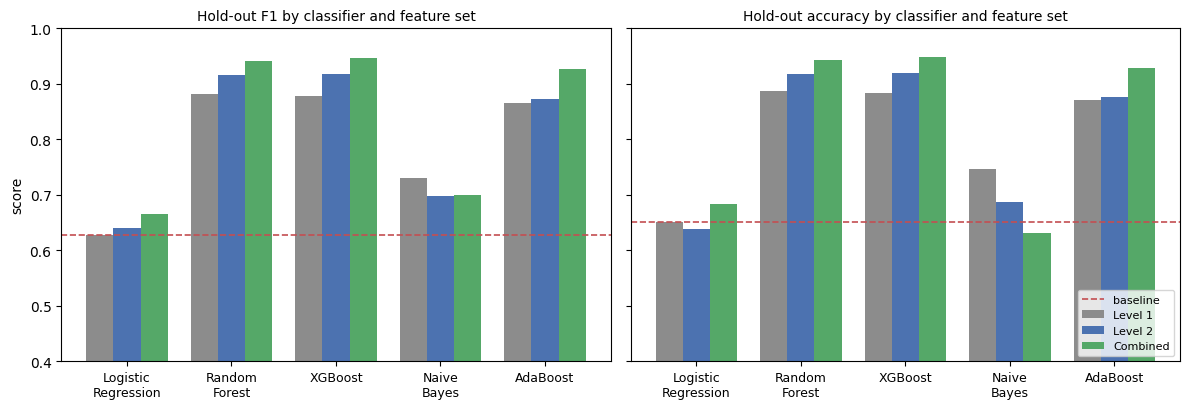

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
colors = {"Level 1": "#8C8C8C", "Level 2": "#4C72B0", "Combined": "#55A868"}
x = np.arange(len(CLASSIFIERS)); w = 0.26
for ax, metric in zip(axes, ["f1", "accuracy"]):
    piv = default_view.pivot(index="classifier", columns="feature_set", values=metric)[list(FEATURE_SETS)].loc[CLASSIFIERS]
    for i, fs in enumerate(FEATURE_SETS):
        ax.bar(x + (i - 1) * w, piv[fs], w, label=fs, color=colors[fs])
    ax.axhline(base["test_default"][metric], color="#C44E52", linestyle="--", linewidth=1.2, label="baseline")
    ax.set_xticks(x, [c.replace(" ", "\n") for c in CLASSIFIERS], fontsize=9)
    ax.set_title(f"Hold-out {metric.upper() if metric == 'f1' else metric} by classifier and feature set", fontsize=10)
    ax.set_ylim(0.4, 1.0)
axes[0].set_ylabel("score"); axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## 7. Best Hyperparameters and Computational Cost

The tuned hyperparameters and cross-validated F1 for every combination, plus the recorded cost: **training time** (whole grid search + CV + refit), **peak memory**, and **inference latency per URL**. The `at grid edge` column lists numeric hyperparameters whose best value landed on the edge of the grid; it is informational, and where F1 is still improving at an edge it is a hint that the grid could be widened.

In [43]:
tune_rows = [{
    "classifier": c, "feature_set": f, "best hyperparameters": r["best_params"],
    "mean CV F1": r["cv_f1"], "std CV F1": r["cv_f1_std"], "tuned threshold": r["tuned_threshold"],
    "at grid edge": ", ".join(r["edge_params"]) or "-",
    "train time (s)": r["train_resources"]["wall_time_s"], "peak memory (MB)": r["train_resources"]["peak_memory_mb"],
    "inference (ms/URL)": r["latency"]["mean_ms"],
} for (c, f), r in RESULTS.items()]
pd.DataFrame(tune_rows).round(4)

,classifier,feature_set,best hyperparameters,mean CV F1,std CV F1,tuned threshold,at grid edge,train time (s),peak memory (MB),inference (ms/URL)
0,Logistic Regression,Level 1,"{'C': 1000, 'class_weight': None, 'solver': 'l...",0.6174,0.0073,0.58,-,0.9506,253.7695,0.0544
1,Logistic Regression,Level 2,"{'C': 100000, 'class_weight': None, 'solver': ...",0.6376,0.0159,0.55,C,2.5523,278.8047,0.0413
2,Logistic Regression,Combined,"{'C': 100, 'class_weight': None, 'solver': 'lb...",0.6576,0.0137,0.54,-,4.6696,288.3047,0.0429
3,Random Forest,Level 1,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es...",0.8920,0.0061,0.54,min_samples_leaf,45.8857,289.1680,1.9672
4,Random Forest,Level 2,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.9121,0.0037,0.47,min_samples_leaf,146.4552,282.6094,2.3375
5,Random Forest,Combined,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.9404,0.0025,0.49,min_samples_leaf,154.3317,288.4961,7.8013
6,XGBoost,Level 1,"{'learning_rate': 0.2, 'max_depth': 5, 'n_esti...",0.8880,0.0084,0.56,learning_rate,36.8088,297.6250,0.9659
7,XGBoost,Level 2,"{'learning_rate': 0.2, 'max_depth': 7, 'n_esti...",0.9127,0.0047,0.57,"learning_rate, max_depth",54.9609,301.2500,1.1795
8,XGBoost,Combined,"{'learning_rate': 0.2, 'max_depth': 7, 'n_esti...",0.9429,0.0037,0.44,"learning_rate, max_depth",42.4544,303.4180,0.4509
9,Naive Bayes,Level 1,{'var_smoothing': 0.01},0.7314,0.0126,0.53,-,0.1284,297.9531,0.1426


## 8. Persist and Verify the 15 Models

Each model was already written to `models/` right after training. This section writes the summary records and then **reloads every file** to prove the persisted models are intact: each reloaded model must reproduce its in-memory hold-out probabilities exactly.

| File | Contents |
|---|---|
| `models/<classifier>__<feature_set>.joblib` (15 files) | A bundle per combination: the fitted model, feature list, best hyperparameters, default and tuned thresholds, version info |
| `all_models_metrics.csv` | Two rows (default / tuned threshold) per combination with metrics, CV score, hyperparameters and resource figures |
| `all_models_metrics.json` | Full record: grid, best parameters, CV, thresholds, hold-out metrics and confusion matrices, resources, environment |
| `models_manifest.csv` | The 15 model files with size and SHA-256, so the testing stage can confirm it loads the intended artefacts |
| `baseline_reference.json` | The recorded baseline metrics every combination is compared against |

To reuse any model: `bundle = joblib.load("models/random_forest__combined.joblib")`, then `bundle["model"].predict_proba(X[bundle["features"]])[:, 1]` (apply `bundle["threshold_default"]` or `bundle["threshold_tuned"]`).

In [44]:
def _native(o):
    if isinstance(o, np.integer):  return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.ndarray):  return o.tolist()
    return str(o)

# ---- verify every persisted model: reload from disk and reproduce the hold-out probabilities
manifest = []
for (clf_name, fs_name), r in RESULTS.items():
    path = model_path(clf_name, fs_name)
    bundle = joblib.load(path)
    X_te = data.iloc[test_idx][bundle["features"]].to_numpy(dtype=np.float64)
    assert bundle["classifier"] == clf_name and bundle["feature_set"] == fs_name
    assert np.allclose(bundle["model"].predict_proba(X_te)[:, 1], r["test_proba"], atol=1e-9), f"reload mismatch: {path}"
    with open(path, "rb") as fh:
        sha = hashlib.sha256(fh.read()).hexdigest()
    manifest.append({"classifier": clf_name, "feature_set": fs_name, "n_features": len(bundle["features"]),
                     "file": path, "size_mb": os.path.getsize(path) / 2**20, "sha256": sha,
                     "threshold_tuned": bundle["threshold_tuned"]})
manifest = pd.DataFrame(manifest)
manifest.to_csv(METRICS_DIR / "models_manifest.csv", index=False)

# ---- flat metrics table and the baseline reference
all_metrics.to_csv(
    METRICS_DIR / "all_models_metrics.csv",
    index=False
)

with open(METRICS_DIR / "baseline_reference.json", "w") as f:
    json.dump({"classifier": "Logistic Regression", "feature_set": "Level 1 (3 features)",
               "best_params": base["best_params"], "cv_f1": base["cv_f1"],
               "test_metrics": {"default (0.5)": base["test_default"], "tuned (Youden J)": base["test_tuned"]}},
              f, indent=2, default=_native)

# ---- full JSON record
record = {
    "milestone": "7 - Model training and tuning",
    "created": datetime.now().isoformat(timespec="seconds"),
    "data": {"source": DATA_PATH, "rows": len(y_all), "train_rows": len(y_train), "test_rows": len(y_test),
             "split": "80/20 stratified", "random_seed": RANDOM_SEED},
    "feature_sets": FEATURE_SETS,
    "cross_validation": {"folds": N_FOLDS, "scoring": "f1", "search": "GridSearchCV"},
    "baseline": {"classifier": "Logistic Regression", "feature_set": "Level 1",
                 "test_metrics_default": base["test_default"]},
    "models": [{
        "classifier": c, "feature_set": f, "features": r["features"], "param_grid": r["param_grid"],
        "best_params": r["best_params"], "cv_f1": r["cv_f1"], "cv_f1_std": r["cv_f1_std"],
        "threshold": {"default": DEFAULT_THRESHOLD, "tuned": r["tuned_threshold"]},
        "test_metrics": {"default (0.5)": r["test_default"], "tuned (Youden J)": r["test_tuned"]},
        "resources": {"training": r["train_resources"], "threshold_tuning": r["threshold_resources"],
                      "inference_latency": r["latency"]},
        "model_file": model_path(c, f),
    } for (c, f), r in RESULTS.items()],
    "environment": {"python": platform.python_version(), "sklearn": sklearn.__version__, "xgboost": xgboost.__version__,
                    "numpy": np.__version__, "pandas": pd.__version__, "psutil": psutil.__version__,
                    "logical_cpus": psutil.cpu_count(logical=True), "ram_gb": round(psutil.virtual_memory().total / 2**30, 1)},
}
with open(METRICS_DIR / "all_models_metrics.json", "w") as f:
    json.dump(record, f, indent=2, default=_native)

print(f"Reloaded and verified {len(manifest)} persisted models (probabilities reproduce exactly).")
manifest[["classifier", "feature_set", "n_features", "file", "size_mb"]].round(2)

Reloaded and verified 15 persisted models (probabilities reproduce exactly).


,classifier,feature_set,n_features,file,size_mb
0,Logistic Regression,Level 1,3,c:\Users\OWEn\Desktop\SCHOOL\## THESIS\THSN02\...,0.00
1,Logistic Regression,Level 2,10,c:\Users\OWEn\Desktop\SCHOOL\## THESIS\THSN02\...,0.00
2,Logistic Regression,Combined,13,c:\Users\OWEn\Desktop\SCHOOL\## THESIS\THSN02\...,0.00
3,Random Forest,Level 1,3,c:\Users\OWEn\Desktop\SCHOOL\## THESIS\THSN02\...,9.48
4,Random Forest,Level 2,10,c:\Users\OWEn\Desktop\SCHOOL\## THESIS\THSN02\...,12.70
5,Random Forest,Combined,13,c:\Users\OWEn\Desktop\SCHOOL\## THESIS\THSN02\...,29.33
6,XGBoost,Level 1,3,c:\Users\OWEn\Desktop\SCHOOL\## THESIS\THSN02\...,0.55
7,XGBoost,Level 2,10,c:\Users\OWEn\Desktop\SCHOOL\## THESIS\THSN02\...,0.87
8,XGBoost,Combined,13,c:\Users\OWEn\Desktop\SCHOOL\## THESIS\THSN02\...,0.83
9,Naive Bayes,Level 1,3,c:\Users\OWEn\Desktop\SCHOOL\## THESIS\THSN02\...,0.00


## 9. Completion Check

**Expected output / measure of completion:** recorded baseline metrics plus 15 trained and tuned model-feature combinations, ready for testing. The cell below asserts each requirement and prints the final summary.

In [46]:
expected = {(c, f) for c in ["Random Forest", "XGBoost", "Logistic Regression", "Naive Bayes", "AdaBoost"]
            for f in ["Level 1", "Level 2", "Combined"]}
assert set(RESULTS) == expected and len(RESULTS) == 15,                  "not all 15 combinations were trained"
assert all(os.path.exists(model_path(c, f)) for c, f in expected),        "a model file is missing"
assert os.path.exists(METRICS_DIR / "baseline_reference.json"),                         "baseline metrics were not recorded"
assert all(all(c in data.columns for c in r["features"]) for r in RESULTS.values())

print("Baseline metrics recorded   : Logistic Regression / Level 1  ->  " +
      " | ".join(f"{k} {base['test_default'][k]:.4f}" for k in ["accuracy", "precision", "recall", "f1", "fpr"]))
print(f"Trained + tuned combinations: {len(RESULTS)} / 15  (5 classifiers x 3 feature configurations)")
print(f"Persisted models            : {len(manifest)} files in ./{MODEL_DIR}/  ({manifest['size_mb'].sum():.1f} MB total)")

best = default_view.sort_values("f1", ascending=False).iloc[0]
print(f"\nBest hold-out F1 at the default threshold: {best['classifier']} on {best['feature_set']} "
      f"(F1 {best['f1']:.4f}, {best['f1'] - base['test_default']['f1']:+.4f} vs baseline)")
print("Status: ready for the formal testing stage.")

Baseline metrics recorded   : Logistic Regression / Level 1  ->  accuracy 0.6515 | precision 0.6731 | recall 0.5890 | f1 0.6283 | fpr 0.2860
Trained + tuned combinations: 15 / 15  (5 classifiers x 3 feature configurations)
Persisted models            : 15 files in ./c:\Users\OWEn\Desktop\SCHOOL\## THESIS\THSN02\PhishEvade\Models/  (54.6 MB total)

Best hold-out F1 at the default threshold: XGBoost on Combined (F1 0.9463, +0.3180 vs baseline)
Status: ready for the formal testing stage.
